In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from config import engine

sns.set_theme(style="whitegrid")

# Load all three tables from SQLite
games     = pd.read_sql("SELECT * FROM games", engine)
snapshots = pd.read_sql("SELECT * FROM price_snapshots", engine, parse_dates=["fetched_at"])
itad      = pd.read_sql("SELECT * FROM itad_price_history", engine, parse_dates=["recorded_at"])

# Join the most recent price snapshot onto each game's metadata
latest = (
    snapshots.sort_values("fetched_at")
    .groupby("app_id").last()
    .reset_index()
)
df = games.merge(latest, on="app_id", how="inner")

# SQLite stores booleans as 0/1 integers — cast to bool so filters work naturally
df["on_sale"] = df["on_sale"].astype(bool)
df["is_free"] = df["is_free"].astype(bool)
snapshots["on_sale"] = snapshots["on_sale"].astype(bool)

# Explode comma-separated genres so each row = one genre (for per-genre plots)
df_genres = (
    df.assign(genre=df["genres"].str.split(","))
    .explode("genre")
)
df_genres["genre"] = df_genres["genre"].str.strip()

print(f"Games: {len(games)}  |  Price snapshots: {len(snapshots)}  |  ITAD rows: {len(itad)}")
print(f"On sale right now: {df['on_sale'].sum()} / {len(df)}")
df.head(3)

Games: 4033  |  Price snapshots: 3580  |  ITAD rows: 2805900
On sale right now: 436 / 3580


,app_id,title,developer,publisher,genres,release_date,metacritic_score,total_reviews,is_free,last_updated,id,fetched_at,current_price,original_price,discount_pct,on_sale
0,10,Counter-Strike,Valve,Valve,Action,"Nov 1, 2000",88.0,168064,False,2026-05-26 20:25:21.458041,392,2026-05-26 20:25:21.460056,9.99,9.99,0,False
1,20,Team Fortress Classic,Valve,Valve,Action,"Apr 1, 1999",NaN,6940,False,2026-05-26 21:54:27.887407,1303,2026-05-26 21:54:27.950744,4.99,4.99,0,False
2,30,Day of Defeat,Valve,Valve,Action,"May 1, 2003",79.0,4424,False,2026-05-26 20:29:38.442464,464,2026-05-26 20:29:38.448623,4.99,4.99,0,False


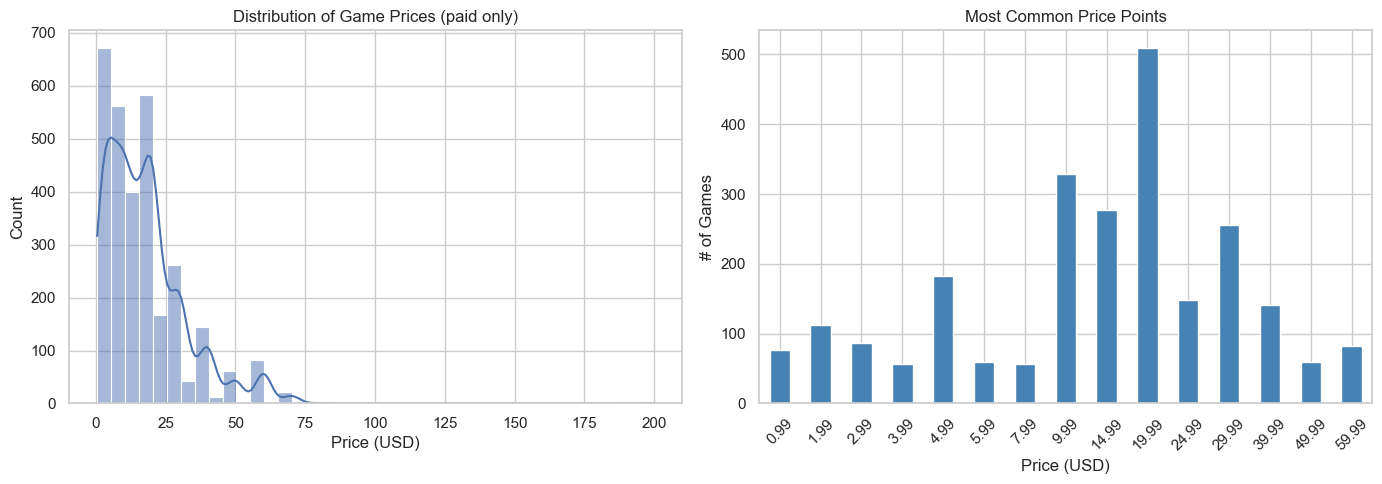

count    3009.00
mean       17.85
std        14.66
min         0.49
25%         6.99
50%        14.99
75%        24.99
max       199.99
Name: current_price, dtype: float64


In [11]:
# Price distribution — how are games priced across the catalog?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

paid = df[df["current_price"] > 0]["current_price"]
sns.histplot(paid, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Game Prices (paid only)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Count")

# Common price points
top_prices = paid.round(2).value_counts().head(15).sort_index()
top_prices.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Most Common Price Points")
axes[1].set_xlabel("Price (USD)")
axes[1].set_ylabel("# of Games")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(paid.describe().round(2))

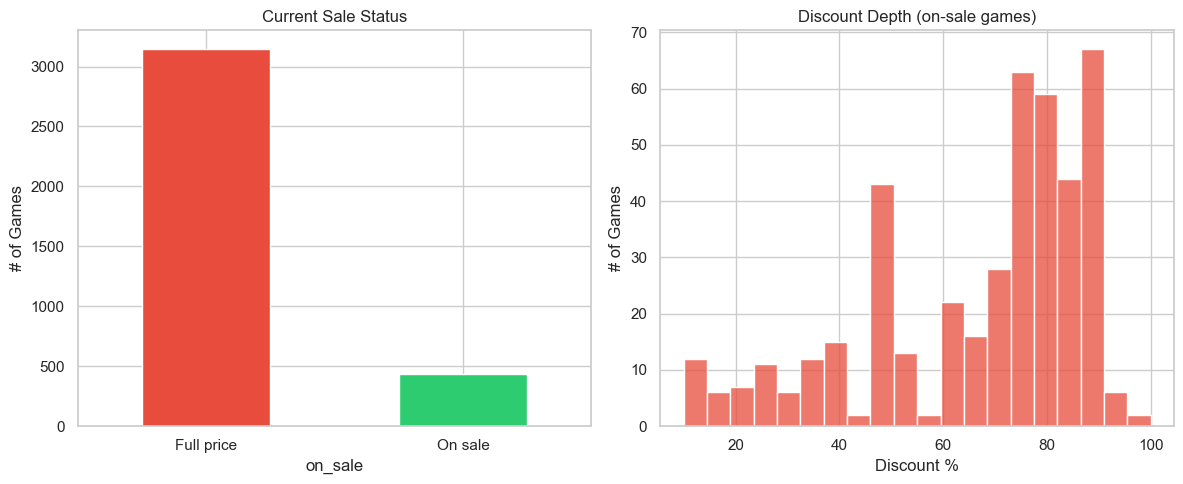

Sale rate: 12.2%
Avg discount when on sale: 66.8%


In [12]:
# How often do games go on sale, and how deep are the discounts?
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# On-sale rate
sale_counts = df["on_sale"].value_counts().rename({True: "On sale", False: "Full price"})
sale_counts.plot(kind="bar", ax=axes[0], color=["#e74c3c", "#2ecc71"])
axes[0].set_title("Current Sale Status")
axes[0].set_ylabel("# of Games")
axes[0].tick_params(axis="x", rotation=0)

# Discount depth (for games currently on sale)
on_sale = df[df["on_sale"] & (df["discount_pct"] > 0)]
sns.histplot(on_sale["discount_pct"], bins=20, ax=axes[1], color="#e74c3c")
axes[1].set_title("Discount Depth (on-sale games)")
axes[1].set_xlabel("Discount %")
axes[1].set_ylabel("# of Games")

plt.tight_layout()
plt.show()

print(f"Sale rate: {df['on_sale'].mean():.1%}")
print(f"Avg discount when on sale: {on_sale['discount_pct'].mean():.1f}%")

C:\Users\danie\AppData\Local\Temp\ipykernel_12580\1090886645.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_sale.index, y=genre_sale["sale_rate"] * 100, palette="Reds_r")


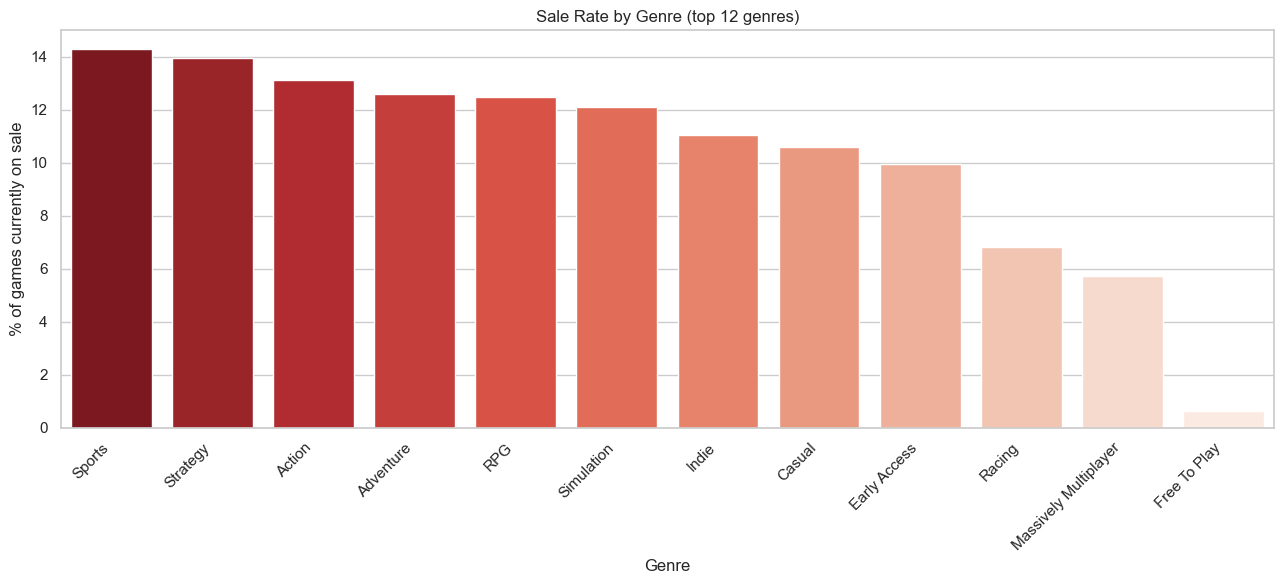

                       on_sale  total  sale_rate
genre                                           
Sports                      16    112   0.142857
Strategy                   124    888   0.139640
Action                     254   1933   0.131402
Adventure                  185   1469   0.125936
RPG                        119    953   0.124869
Simulation                 100    827   0.120919
Indie                      209   1892   0.110465
Casual                      80    756   0.105820
Early Access                18    181   0.099448
Racing                       8    117   0.068376
Massively Multiplayer       15    262   0.057252
Free To Play                 3    491   0.006110


In [13]:
# Sale frequency by genre
top_genres = df_genres["genre"].value_counts().head(12).index
genre_df = df_genres[df_genres["genre"].isin(top_genres)]

plt.figure(figsize=(13, 6))
genre_sale = (
    genre_df.groupby("genre")["on_sale"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "on_sale", "count": "total"})
)
genre_sale["sale_rate"] = genre_sale["on_sale"] / genre_sale["total"]
genre_sale = genre_sale.sort_values("sale_rate", ascending=False)

sns.barplot(x=genre_sale.index, y=genre_sale["sale_rate"] * 100, palette="Reds_r")
plt.title("Sale Rate by Genre (top 12 genres)")
plt.xlabel("Genre")
plt.ylabel("% of games currently on sale")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(genre_sale[["on_sale", "total", "sale_rate"]].to_string())

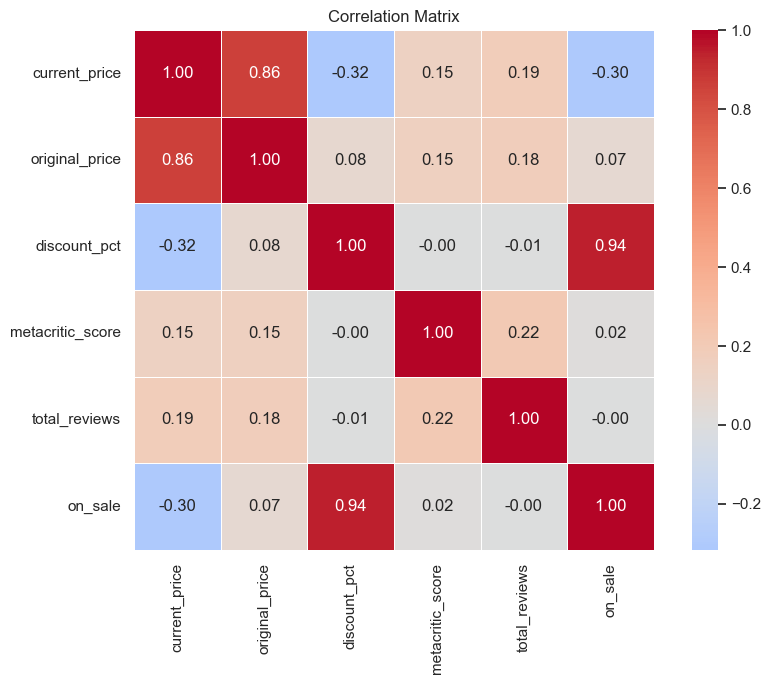

In [14]:
# Correlation matrix — which numeric features relate to being on sale?
numeric_cols = ["current_price", "original_price", "discount_pct", "metacritic_score", "total_reviews", "on_sale"]
corr_df = df[numeric_cols].copy()
corr_df["on_sale"] = corr_df["on_sale"].astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_df.corr(),
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    square=True, linewidths=0.5,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

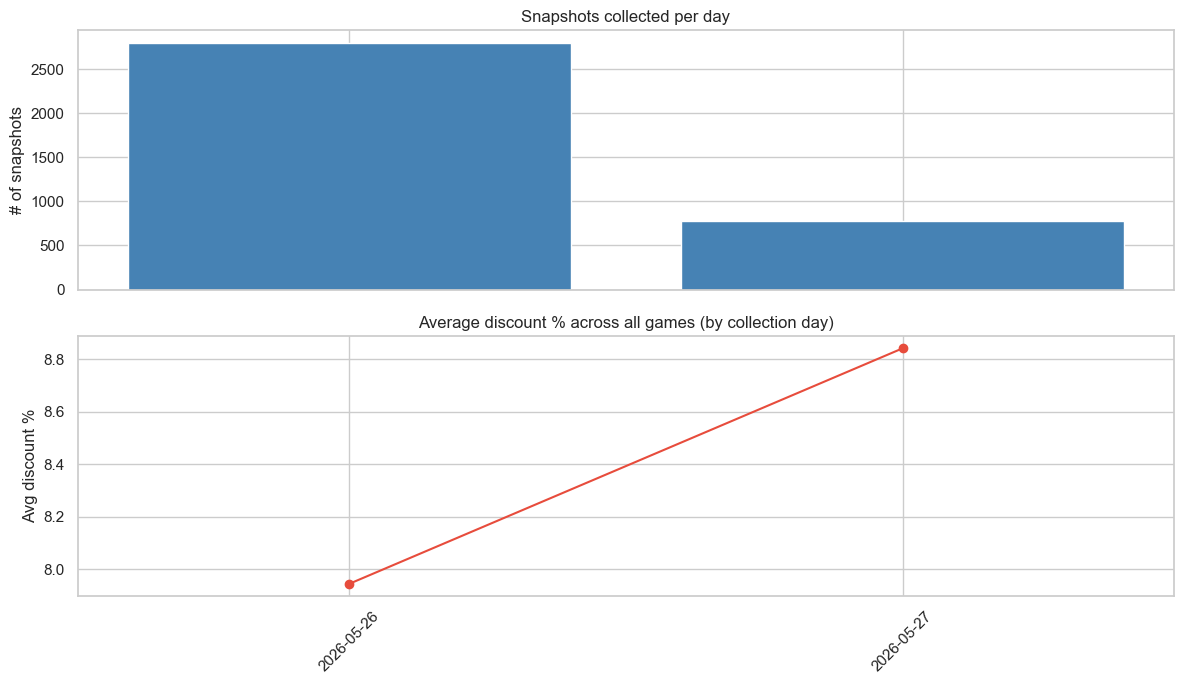


Top 10 deepest discounts right now:
                               title  original_price  current_price  real_discount_pct
      3D PUZZLE - Post-Apocalyptic 3          199.99           9.99                 95
                         Upside Down           29.99           1.49                 95
             Warhammer: Vermintide 2           29.99           1.49                 95
                    Midnight's Curse            9.99           0.79                 92
                      Super Meat Boy           14.99           1.19                 92
                             LineVox            9.99           0.89                 91
                            Dead Age           14.99           1.49                 90
Battlefleet Gothic: Armada (Classic)           14.99           1.49                 90
                            UBERMOSH            4.99           0.49                 90
                                Eron            4.99           0.49                 90


In [15]:
# Price history over time — how many snapshots per day and average discount
snapshots["date"] = snapshots["fetched_at"].dt.date

daily = snapshots.groupby("date").agg(
    games_checked=("app_id", "count"),
    pct_on_sale=("on_sale", "mean"),
    avg_discount=("discount_pct", "mean"),
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].bar(daily["date"].astype(str), daily["games_checked"], color="steelblue")
axes[0].set_title("Snapshots collected per day")
axes[0].set_ylabel("# of snapshots")

axes[1].plot(daily["date"].astype(str), daily["avg_discount"], marker="o", color="#e74c3c")
axes[1].set_title("Average discount % across all games (by collection day)")
axes[1].set_ylabel("Avg discount %")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Recompute discount from actual prices to override any bad values from Steam's API
df["real_discount_pct"] = (
    ((df["original_price"] - df["current_price"]) / df["original_price"] * 100)
    .clip(0, 100)
    .round(0)
    .astype("Int64")
    .where(df["original_price"] > 0)
)
on_sale_now = df[df["on_sale"] & (df["current_price"] > 0) & (df["real_discount_pct"] > 0)]

print("\nTop 10 deepest discounts right now:")
print(
    on_sale_now[["title", "original_price", "current_price", "real_discount_pct"]]
    .sort_values("real_discount_pct", ascending=False)
    .head(10)
    .to_string(index=False)
)

## ITAD Historical Analysis
The cells below derive per-game sale statistics from ITAD history — these become the core ML features.

In [16]:
from datetime import datetime, timezone

# Per-game ITAD statistics — these become ML features
steam_itad = itad[itad["shop"] == "Steam"].copy()
steam_itad = steam_itad.sort_values(["app_id", "recorded_at"])

# Only look at actual sale events (price was reduced)
sales_only = steam_itad[steam_itad["discount_pct"] > 0].copy()

now = datetime.now(timezone.utc)

itad_features = (
    steam_itad.groupby("app_id")
    .agg(
        historical_low=("price", "min"),
        avg_discount=("discount_pct", "mean"),
        max_discount=("discount_pct", "max"),
        sale_count=("discount_pct", lambda x: (x > 0).sum()),
        first_seen=("recorded_at", "min"),
        last_seen=("recorded_at", "max"),
    )
    .reset_index()
)

# Days since last sale per game
last_sale = (
    sales_only.groupby("app_id")["recorded_at"]
    .max()
    .reset_index()
    .rename(columns={"recorded_at": "last_sale_at"})
)
itad_features = itad_features.merge(last_sale, on="app_id", how="left")
itad_features["days_since_last_sale"] = (
    (now - itad_features["last_sale_at"].dt.tz_localize("UTC", ambiguous="NaT", nonexistent="NaT")
     .fillna(itad_features["last_sale_at"]))
    .dt.total_seconds() / 86400
).round(1)

# Average gap between sales (sale cadence)
def avg_days_between_sales(group):
    dates = group["recorded_at"].sort_values()
    if len(dates) < 2:
        return None
    gaps = dates.diff().dropna().dt.total_seconds() / 86400
    return round(gaps.mean(), 1)

cadence = (
    sales_only.groupby("app_id")
    .apply(avg_days_between_sales, include_groups=False)
    .reset_index()
    .rename(columns={0: "avg_days_between_sales"})
)
itad_features = itad_features.merge(cadence, on="app_id", how="left")

print(f"Games with ITAD features: {len(itad_features)}")
print(f"Games that have been on sale at least once: {(itad_features['sale_count'] > 0).sum()}")
itad_features.describe().round(2)

C:\Users\danie\AppData\Local\Temp\ipykernel_12580\3042447540.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(itad_features["last_sale_at"]))


Games with ITAD features: 3867
Games that have been on sale at least once: 3239


,app_id,historical_low,avg_discount,max_discount,sale_count,first_seen,last_seen,last_sale_at,days_since_last_sale,avg_days_between_sales
count,3867.00,3867.00,3867.00,3867.00,3867.00,3867,3867,3239,3239.00,3162.00
mean,859496.29,4.39,22.90,59.97,44.81,2018-03-09 01:50:09.317300224,2024-06-20 10:21:39.228859648,2025-06-13 06:23:48.583513600,348.54,57.75
min,10.00,0.00,0.00,0.00,0.00,2012-09-04 21:43:12,2013-08-04 15:58:49,2013-05-01 17:26:08,0.00,6.90
25%,284445.00,0.00,13.25,40.00,10.00,2014-11-09 12:52:23,2024-02-11 07:55:23,2026-03-19 18:28:23,23.00,40.80
50%,567680.00,1.99,25.76,75.00,42.00,2017-11-03 00:45:40,2026-04-16 19:20:15,2026-04-16 19:19:53,41.00,48.60
75%,1213455.00,5.54,34.04,85.00,72.00,2021-02-25 05:13:06,2026-05-10 17:15:57,2026-05-04 19:33:10,69.00,61.40
max,4714600.00,79.99,45.82,100.00,245.00,2026-05-27 15:33:29,2026-05-27 19:18:43,2026-05-27 19:18:38,4774.10,1055.70
std,836243.85,6.65,13.31,32.29,36.26,NaN,NaN,NaN,790.34,44.74


C:\Users\danie\AppData\Local\Temp\ipykernel_12580\1657797108.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="month_name", y="sale_events", data=monthly, palette="Blues_d", ax=axes[0])


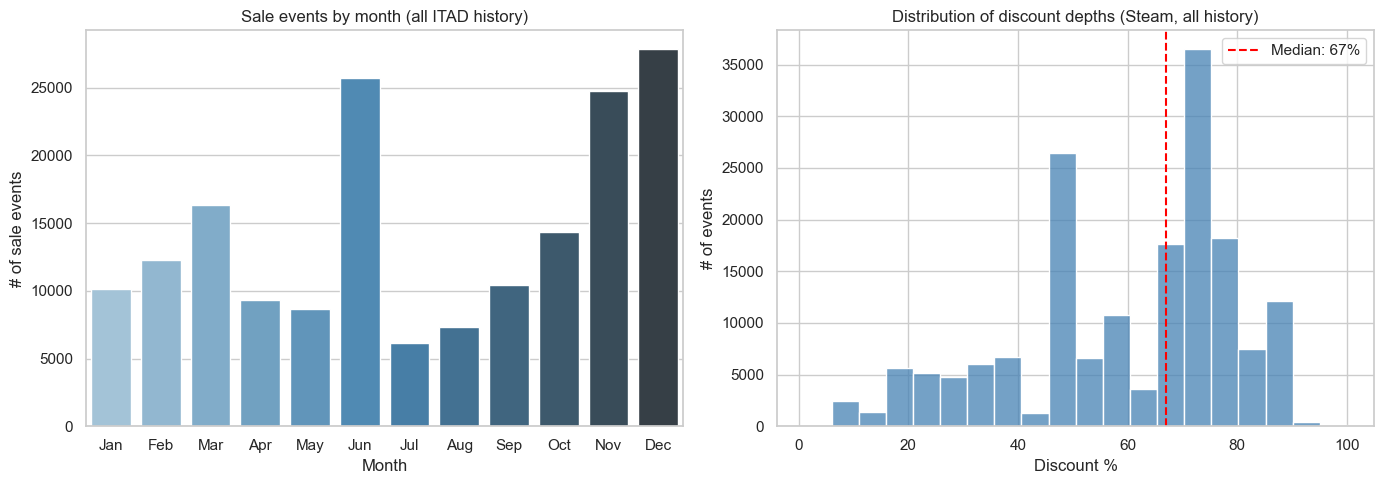

Top sale months:
 month  sale_events month_name
    12        27836        Dec
     6        25725        Jun
    11        24766        Nov
     3        16344        Mar
    10        14377        Oct
     2        12255        Feb
     9        10406        Sep
     1        10124        Jan
     4         9325        Apr
     5         8640        May
     8         7331        Aug
     7         6152        Jul


In [17]:
# Seasonal sale patterns — which months do Steam discounts cluster in?
sales_only["month"] = sales_only["recorded_at"].dt.month
monthly = sales_only.groupby("month").size().reset_index(name="sale_events")
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly["month_name"] = monthly["month"].apply(lambda m: month_names[m-1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x="month_name", y="sale_events", data=monthly, palette="Blues_d", ax=axes[0])
axes[0].set_title("Sale events by month (all ITAD history)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("# of sale events")

# Discount depth distribution
sns.histplot(sales_only["discount_pct"], bins=20, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of discount depths (Steam, all history)")
axes[1].set_xlabel("Discount %")
axes[1].set_ylabel("# of events")
axes[1].axvline(sales_only["discount_pct"].median(), color="red", linestyle="--", label=f'Median: {sales_only["discount_pct"].median():.0f}%')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Top sale months:")
print(monthly.sort_values("sale_events", ascending=False).to_string(index=False))

In [18]:
# Full feature matrix — join everything together, ready for Phase 2 modelling
import numpy as np

full = df.merge(itad_features, on="app_id", how="left")

# Parse release year from Steam's date string
full["release_year"] = pd.to_numeric(
    full["release_date"].str.extract(r"(\d{4})")[0], errors="coerce"
)
full["game_age_days"] = (pd.Timestamp.now() - pd.to_datetime(full["release_date"], errors="coerce")).dt.days

# Price tier buckets (common Steam price points)
bins   = [0, 5, 10, 15, 20, 30, 40, 60, 9999]
labels = ["<$5","$5","$10","$15","$20","$30","$40","$60+"]
full["price_tier"] = pd.cut(full["original_price"], bins=bins, labels=labels, right=False)

# Is the game at or near its historical low right now?
full["at_historical_low"] = (
    (full["current_price"] <= full["historical_low"] * 1.05) &
    full["current_price"].notna() &
    full["historical_low"].notna()
)

# Summary of what we have
feature_cols = [
    "app_id", "title", "original_price", "current_price", "real_discount_pct",
    "on_sale", "game_age_days", "metacritic_score", "total_reviews",
    "historical_low", "avg_discount", "max_discount", "sale_count",
    "days_since_last_sale", "avg_days_between_sales", "at_historical_low",
    "price_tier", "genres",
]
feature_df = full[feature_cols].copy()

print(f"Feature matrix: {feature_df.shape[0]} games x {feature_df.shape[1]} columns")
print(f"\nMissing values:")
print(feature_df.isnull().sum()[feature_df.isnull().sum() > 0])
print(f"\nSample — games overdue for a sale (days_since_last_sale > avg gap):")
overdue = feature_df[
    feature_df["days_since_last_sale"] > feature_df["avg_days_between_sales"]
].sort_values("days_since_last_sale", ascending=False)
print(overdue[["title","original_price","days_since_last_sale","avg_days_between_sales","max_discount"]].head(10).to_string(index=False))

Feature matrix: 3580 games x 18 columns

Missing values:
original_price             571
current_price              571
real_discount_pct          571
game_age_days               15
metacritic_score          2168
historical_low              43
avg_discount                43
max_discount                43
sale_count                  43
days_since_last_sale       552
avg_days_between_sales     620
price_tier                 571
dtype: int64

Sample — games overdue for a sale (days_since_last_sale > avg gap):
                          title  original_price  days_since_last_sale  avg_days_between_sales  max_discount
                   Kingdom Wars             NaN                4359.9                    49.3          85.0
              The Desolate Hope             NaN                4178.0                    28.1          80.0
The Four Kings Casino and Slots             NaN                4048.0                    68.1          20.0
          Rise of Flight United             NaN          